# 02 · Exploratory Data Analysis

**Goal:** understand the target, find which features relate to subscription, and spot what needs
scaling, transforming, binning or dropping before modeling.

Only tools from the course are used: pandas, numpy, matplotlib and seaborn.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

df = pd.read_csv('../data/bank-full.csv')
df['y_num'] = (df['y'] == 'yes').astype(int)   # helper column for rates
num_cols = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
overall = df['y_num'].mean()
print(df.shape, f'overall yes rate = {overall:.1%}')

(45211, 18) overall yes rate = 11.7%


## 1. Target: is it balanced?

      rows     %
y               
no   39922  88.3
yes   5289  11.7


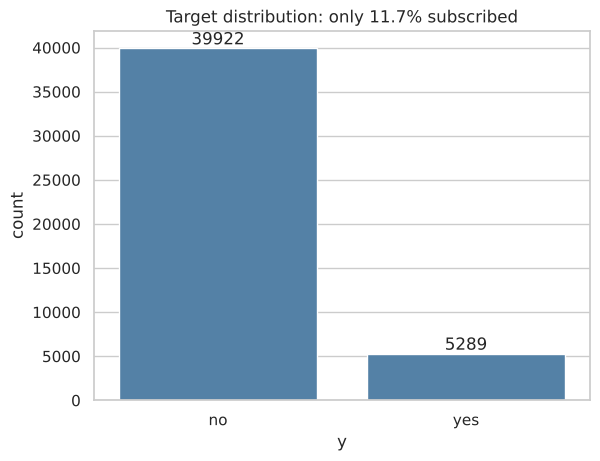

A model that always predicts 'no' is 88.3% accurate but finds 0 subscribers.


In [2]:
counts = df['y'].value_counts()
print(pd.concat([counts, (counts / len(df) * 100).round(1)], axis=1, keys=['rows', '%']))

ax = sns.countplot(data=df, x='y', order=['no', 'yes'], color='steelblue')
ax.bar_label(ax.containers[0], fmt='%d')
ax.set_title('Target distribution: only 11.7% subscribed')
plt.show()

print(f"A model that always predicts 'no' is {1 - overall:.1%} accurate but finds 0 subscribers.")

**Imbalanced:** about 1 yes for every 7.5 no. Accuracy is misleading here, so we will use
balanced accuracy, recall, precision, F1 and ROC-AUC.

## 2. Numeric features: distributions and skew

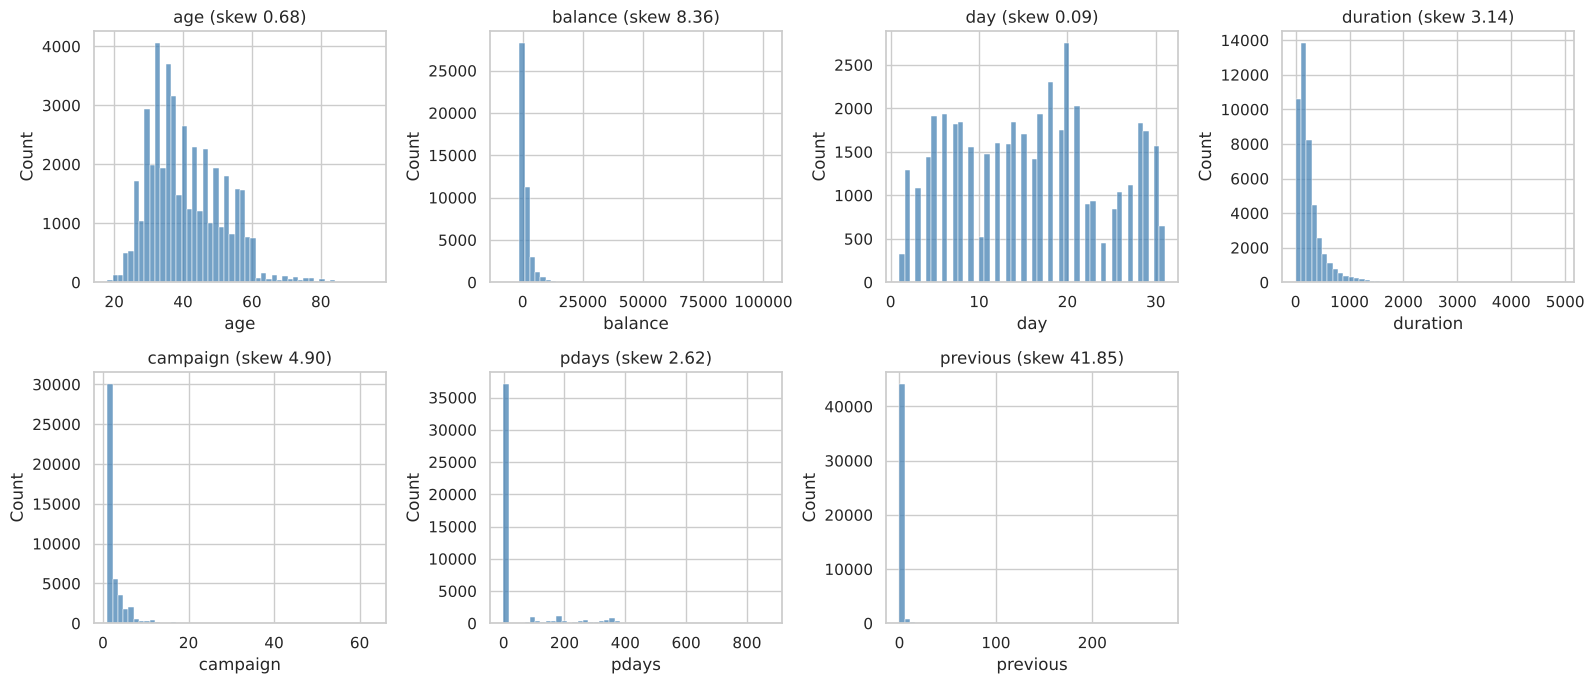

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], bins=50, ax=ax, color='steelblue')
    ax.set_title(f'{col} (skew {df[col].skew():.2f})')
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

In [4]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

summary = pd.DataFrame({
    'skew': df[num_cols].skew().round(2),
    'iqr_outliers': [iqr_outliers(df[c]) for c in num_cols],
    'median_yes': df[df.y_num == 1][num_cols].median(),
    'median_no': df[df.y_num == 0][num_cols].median(),
})
summary['outlier_%'] = (summary['iqr_outliers'] / len(df) * 100).round(1)
summary

,skew,iqr_outliers,median_yes,median_no,outlier_%
age,0.68,487,38.0,39.0,1.1
balance,8.36,4729,733.0,417.0,10.5
day,0.09,0,15.0,16.0,0.0
duration,3.14,3235,426.0,164.0,7.2
campaign,4.90,3064,2.0,2.0,6.8
pdays,2.62,8257,-1.0,-1.0,18.3
previous,41.85,8257,0.0,0.0,18.3


- `balance`, `campaign`, `previous` are strongly right-skewed (and `balance` has negatives).
- The `pdays` / `previous` "outliers" are just the 18.3% of clients contacted before: the IQR collapses because 75% of rows are -1 or 0.
- `previous` has one extreme value (275); the next highest is 58.

In [5]:
print('Top 5 previous:', df['previous'].nlargest(5).tolist())
print('Top 5 campaign:', df['campaign'].nlargest(5).tolist())
print('Negative balances:', (df['balance'] < 0).sum(), '| zero balances:', (df['balance'] == 0).sum())

Top 5 previous: [275, 58, 55, 51, 41]
Top 5 campaign: [63, 58, 55, 51, 50]
Negative balances: 3766 | zero balances: 3514


## 3. Numeric features vs the target

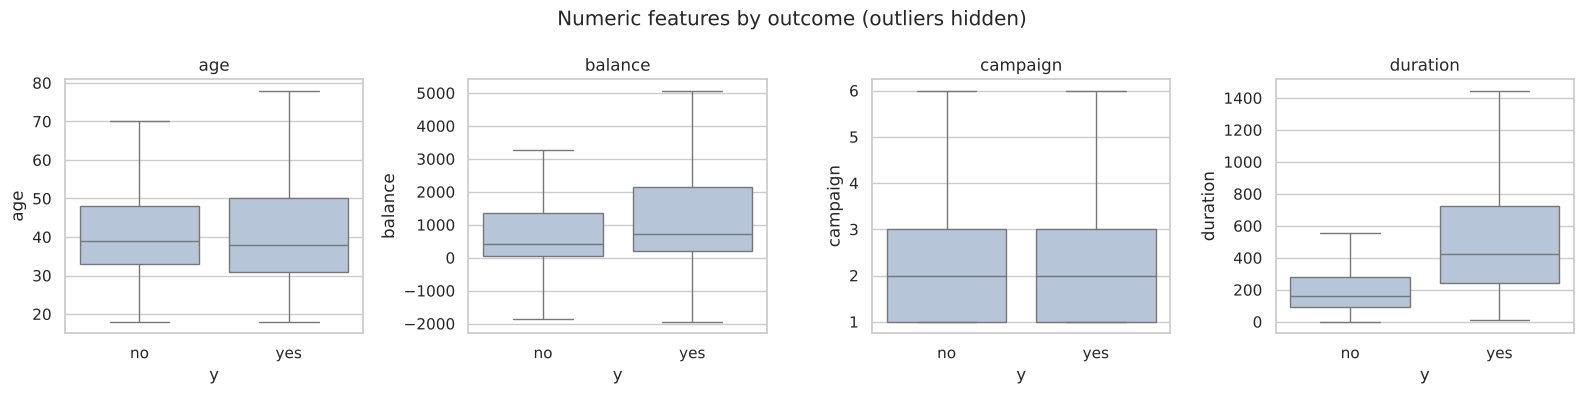

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ['age', 'balance', 'campaign', 'duration']):
    sns.boxplot(data=df, x='y', y=col, order=['no', 'yes'], ax=ax, showfliers=False, color='lightsteelblue')
    ax.set_title(col)
plt.suptitle('Numeric features by outcome (outliers hidden)')
plt.tight_layout()
plt.show()

### Subscription rate across bins

Binning shows **non-linear** patterns that a straight correlation misses.

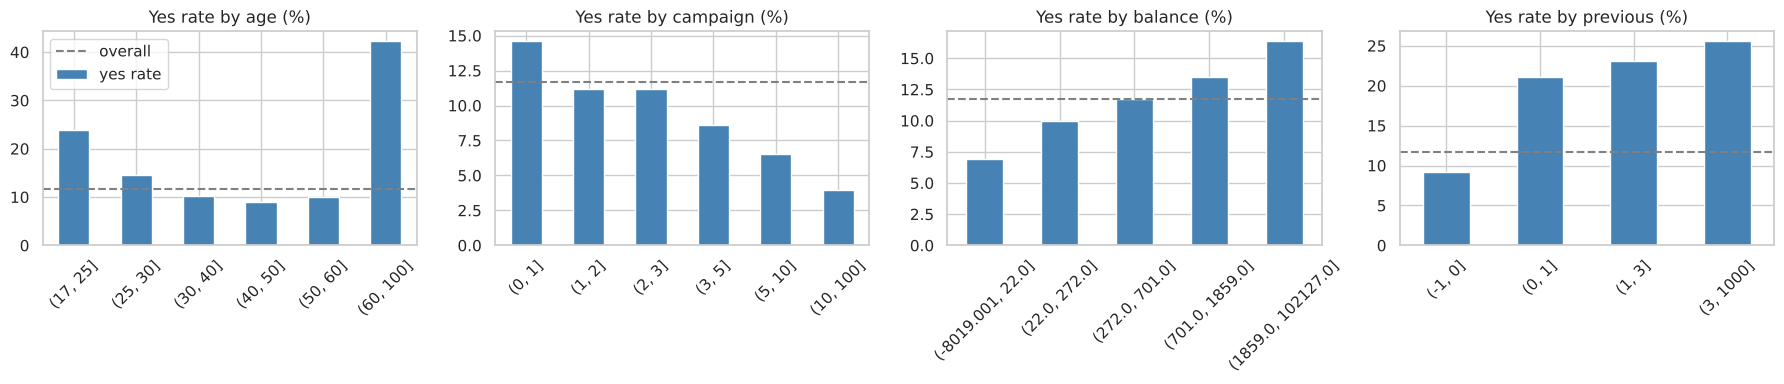

           count   mean
age                    
(17, 25]    1336  0.240
(25, 30]    5694  0.145
(30, 40]   17687  0.102
(40, 50]   11239  0.091
(50, 60]    8067  0.101
(60, 100]   1188  0.423 

           count   mean
campaign               
(0, 1]     17544  0.146
(1, 2]     12505  0.112
(2, 3]      5521  0.112
(3, 5]      5286  0.086
(5, 10]     3159  0.065
(10, 100]   1196  0.039 

                    count   mean
balance                         
(-8019.001, 22.0]    9053  0.070
(22.0, 272.0]        9060  0.100
(272.0, 701.0]       9017  0.117
(701.0, 1859.0]      9039  0.135
(1859.0, 102127.0]   9042  0.164 

           count   mean
previous               
(-1, 0]    36954  0.092
(0, 1]      2772  0.210
(1, 3]      3248  0.231
(3, 1000]   2237  0.256 



In [7]:
bins = {
    'age':      pd.cut(df['age'], [17, 25, 30, 40, 50, 60, 100]),
    'campaign': pd.cut(df['campaign'], [0, 1, 2, 3, 5, 10, 100]),
    'balance':  pd.qcut(df['balance'], 5),
    'previous': pd.cut(df['previous'], [-1, 0, 1, 3, 1000]),
}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, b) in zip(axes, bins.items()):
    rate = df.groupby(b, observed=True)['y_num'].mean() * 100
    rate.plot(kind='bar', ax=ax, color='steelblue', label='yes rate')
    ax.axhline(overall * 100, color='grey', ls='--', label='overall')
    ax.set_title(f'Yes rate by {name} (%)')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)
axes[0].legend()
plt.tight_layout()
plt.show()

for name, b in bins.items():
    print(df.groupby(b, observed=True)['y_num'].agg(['count', 'mean']).round(3), '\n')

- **age** is U-shaped: 24.0% at 18–25 and 42.3% at 60+, vs 9–10% in between → candidate for age-group bins.
- **campaign**: more calls, fewer yeses (14.6% at 1 call → 3.9% at 11+).
- **balance**: the rate rises from 7.0% (lowest fifth) to 16.4% (top fifth).
- **previous**: any prior contact more than doubles the rate (9.2% → 21–26%).

In [8]:
contacted = df[df['pdays'] > -1]
pdays_bins = pd.cut(contacted['pdays'], [0, 90, 180, 365, 900])
contacted.groupby(pdays_bins, observed=True)['y_num'].agg(['count', 'mean']).round(3)

,count,mean
pdays,,
"(0, 90]",718,0.350
"(90, 180]",2480,0.274
"(180, 365]",4416,0.178
"(365, 900]",643,0.292


## 4. Categorical features vs the target

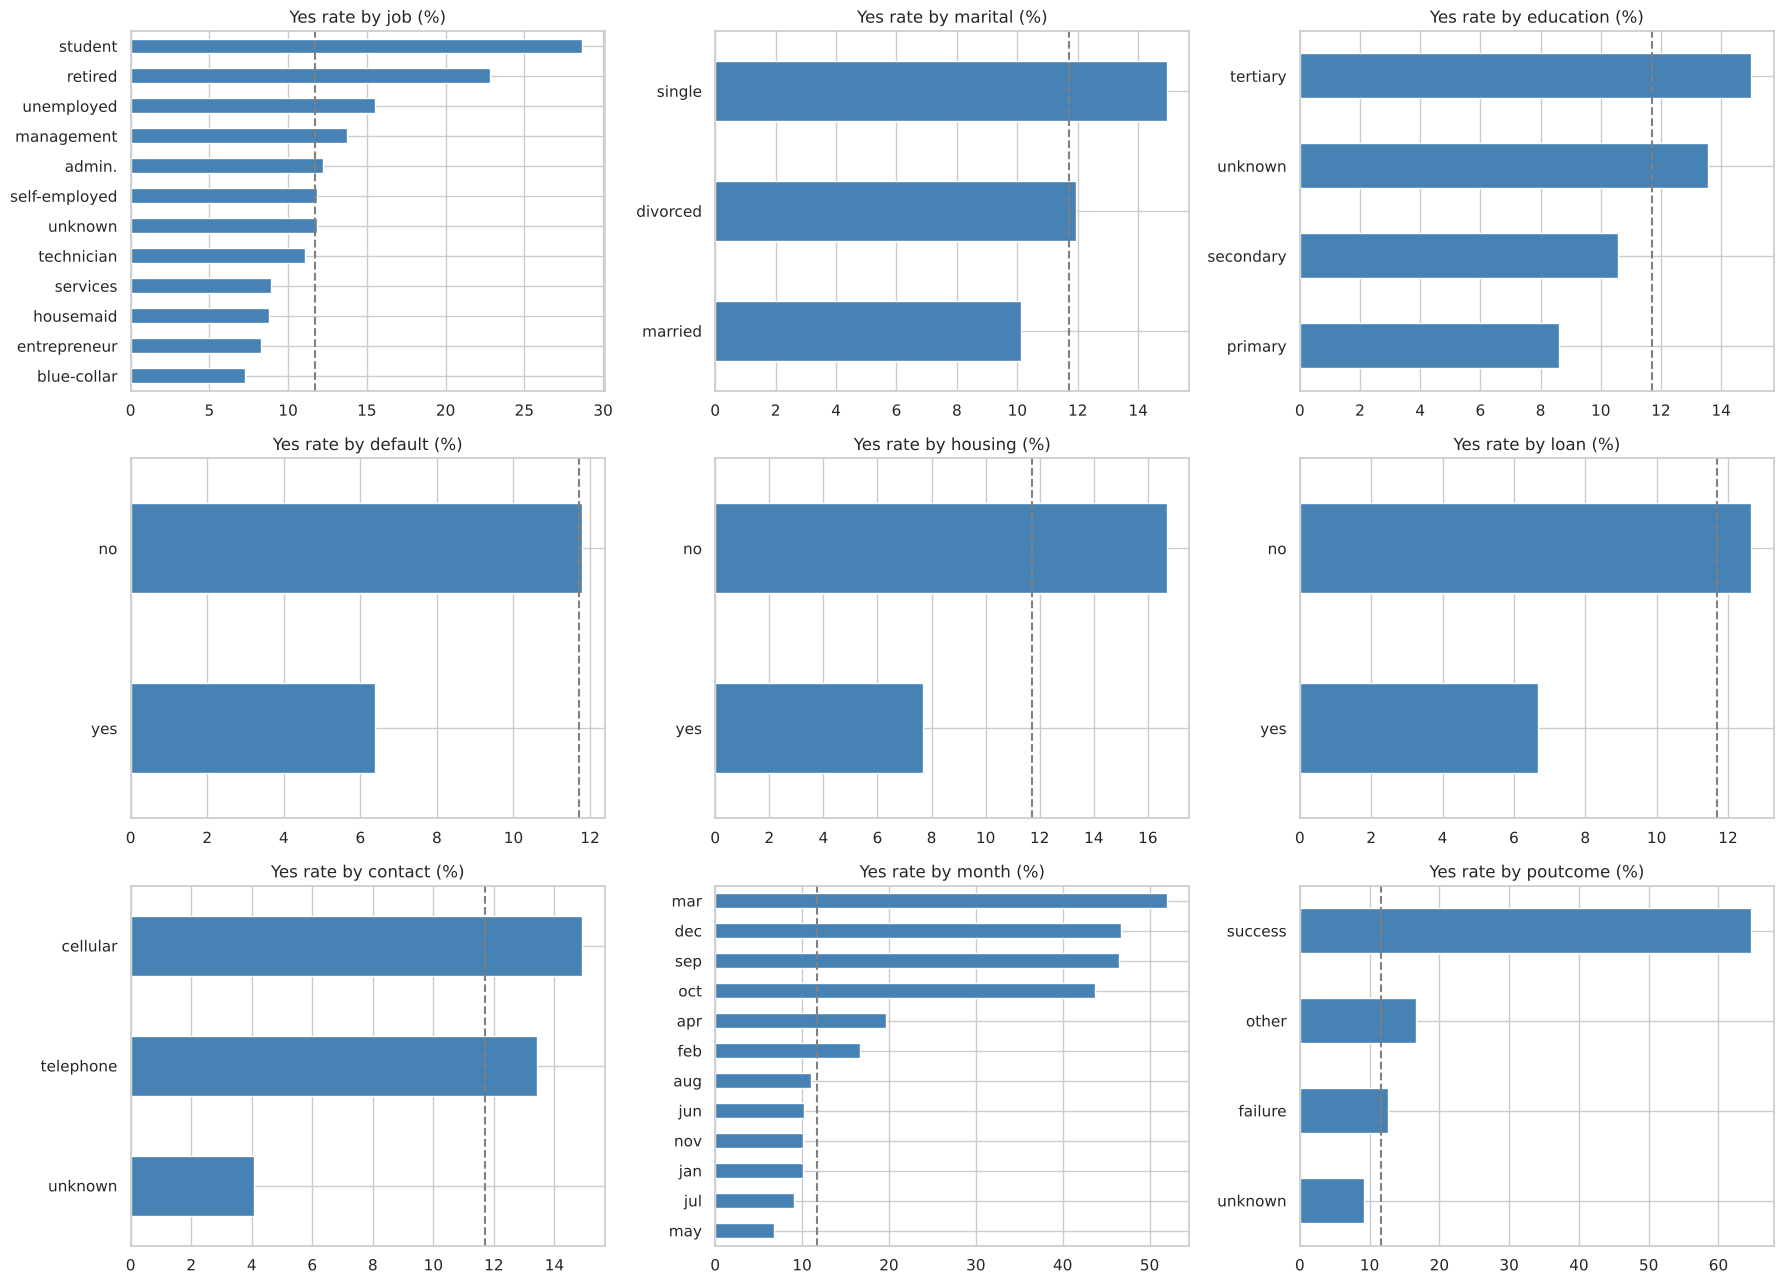

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(18, 13))
for ax, col in zip(axes.flat, cat_cols):
    rate = (df.groupby(col)['y_num'].mean() * 100).sort_values()
    rate.plot(kind='barh', ax=ax, color='steelblue')
    ax.axvline(overall * 100, color='grey', ls='--')
    ax.set_title(f'Yes rate by {col} (%)')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

In [10]:
rows = []
for col in cat_cols:
    rate = df.groupby(col)['y_num'].mean() * 100
    rows.append({'feature': col, 'lowest_%': rate.min().round(1), 'highest_%': rate.max().round(1),
                 'spread_points': (rate.max() - rate.min()).round(1), 'levels': df[col].nunique()})
pd.DataFrame(rows).sort_values('spread_points', ascending=False).reset_index(drop=True)

,feature,lowest_%,highest_%,spread_points,levels
0,poutcome,9.2,64.7,55.6,4
1,month,6.7,52.0,45.3,12
2,job,7.3,28.7,21.4,12
3,contact,4.1,14.9,10.8,3
4,housing,7.7,16.7,9.0,2
5,education,8.6,15.0,6.4,4
6,loan,6.7,12.7,6.0,2
7,default,6.4,11.8,5.4,2
8,marital,10.1,14.9,4.8,3


The **spread** (highest minus lowest subscription rate across a column's categories) ranks how strongly
each categorical feature separates subscribers. `poutcome` and `month` lead; `default` is weak and 98.2% "no".

In [11]:
print(df.groupby('poutcome')['y_num'].agg(['count', 'mean']).round(3))
print()
print((df['default'].value_counts(normalize=True) * 100).round(1))

          count   mean
poutcome              
failure    4901  0.126
other      1840  0.167
success    1511  0.647
unknown   36959  0.092

default
no     98.2
yes     1.8
Name: proportion, dtype: float64


### Month: call volume vs subscription rate

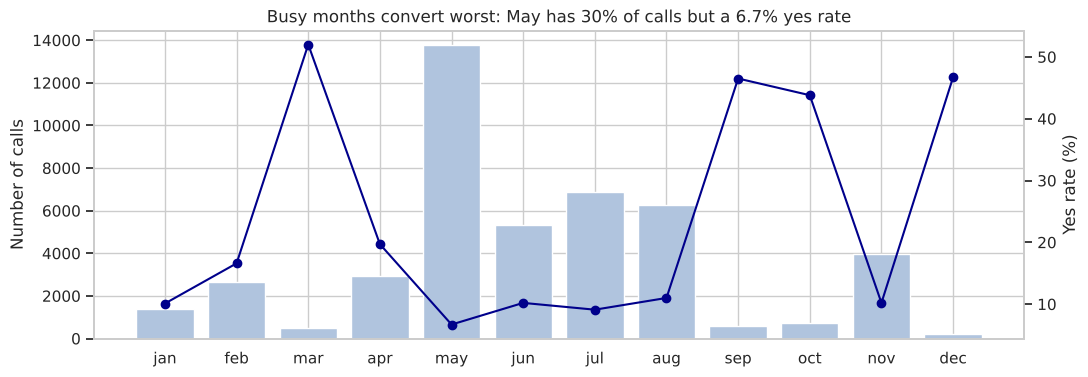

,calls,rate
month,,
jan,1403,10.1
feb,2649,16.6
mar,477,52.0
apr,2932,19.7
may,13766,6.7
jun,5341,10.2
jul,6895,9.1
aug,6247,11.0
sep,579,46.5


In [12]:
order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
m = df.groupby('month')['y_num'].agg(calls='count', rate='mean').reindex(order)
m['rate'] = (m['rate'] * 100).round(1)

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.bar(m.index, m['calls'], color='lightsteelblue', label='calls')
ax1.set_ylabel('Number of calls')
ax2 = ax1.twinx()
ax2.plot(m.index, m['rate'], color='darkblue', marker='o', label='yes rate %')
ax2.set_ylabel('Yes rate (%)')
ax2.grid(False)
plt.title('Busy months convert worst: May has 30% of calls but a 6.7% yes rate')
plt.show()
m

High rates (44–52% in Mar, Sep, Oct, Dec) sit in months with very few calls, so `month` partly
reflects **campaign intensity**, not only the calendar.

### Contact channel: is "unknown" real?

In [13]:
pd.crosstab(df['contact'], df['month'])[order]

month,jan,feb,mar,apr,may,jun,jul,aug,sep,oct,nov,dec
contact,,,,,,,,,,,,
cellular,1265,2362,417,2727,5331,729,5767,5950,466,557,3540,174
telephone,129,274,53,199,460,80,852,246,66,131,379,37
unknown,9,13,7,6,7975,4532,276,51,47,50,51,3


12,507 of the 13,020 `unknown` contacts fall in May–June: an early **recording gap**, not a real channel.
It converts at only 4.1%, so it is kept as its own category.

## 5. Are the rows in time order?

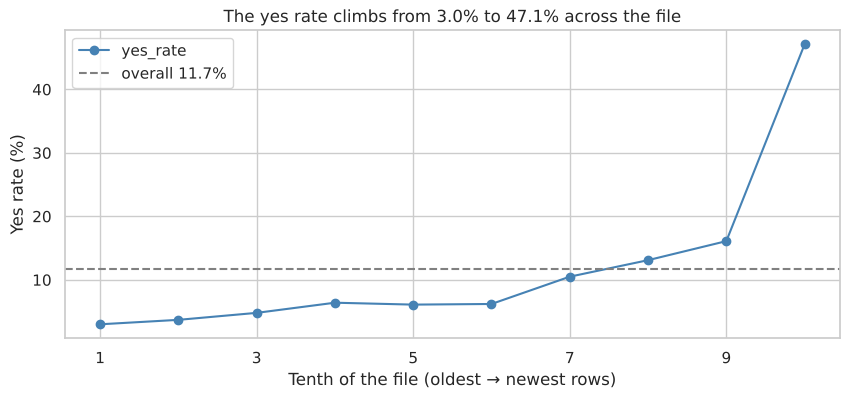

,yes_rate,first_month,last_month
1,3.0,may,may
2,3.7,may,jun
3,4.8,jun,jul
4,6.4,jul,jul
5,6.1,jul,aug
6,6.2,aug,nov
7,10.5,nov,apr
8,13.1,apr,may
9,16.1,may,aug
10,47.1,aug,nov


In [14]:
tenth = pd.qcut(df.index, 10, labels=range(1, 11))
t = df.groupby(tenth, observed=True).agg(yes_rate=('y_num', 'mean'),
                                         first_month=('month', 'first'),
                                         last_month=('month', 'last'))
t['yes_rate'] = (t['yes_rate'] * 100).round(1)

ax = t['yes_rate'].plot(marker='o', figsize=(10, 4), color='steelblue')
ax.axhline(overall * 100, color='grey', ls='--', label='overall 11.7%')
ax.set_xlabel('Tenth of the file (oldest → newest rows)')
ax.set_ylabel('Yes rate (%)')
ax.set_title('The yes rate climbs from 3.0% to 47.1% across the file')
ax.legend()
plt.show()
t

The file has no year column, but its rows are sorted by date. Later campaigns called fewer, better-targeted
clients. This is a **limitation**: results on a random split may look better than on future campaigns.

## 6. Correlations

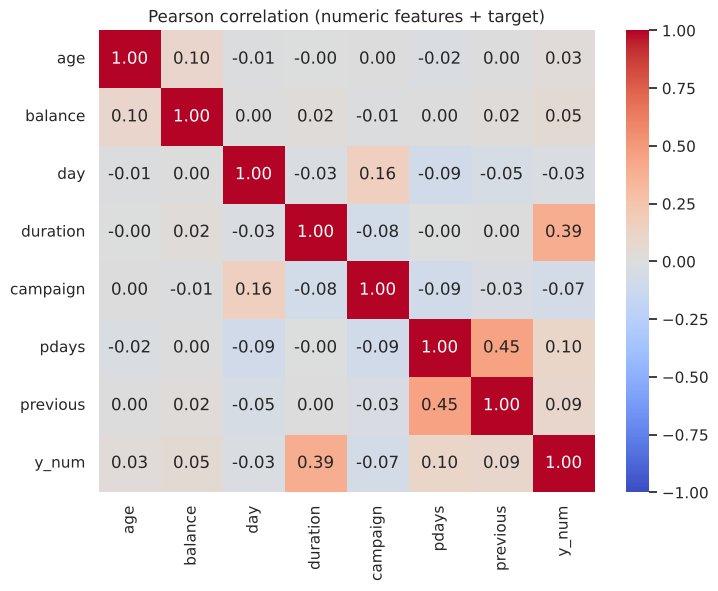

In [15]:
corr = df[num_cols + ['y_num']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Pearson correlation (numeric features + target)')
plt.show()

In [16]:
target_corr = pd.DataFrame({
    'pearson': df[num_cols].corrwith(df['y_num']),
    'spearman': df[num_cols].corrwith(df['y_num'], method='spearman'),
}).round(3).sort_values('spearman', key=abs, ascending=False)
target_corr

,pearson,spearman
duration,0.395,0.342
previous,0.093,0.169
pdays,0.104,0.154
balance,0.053,0.100
campaign,-0.073,-0.084
day,-0.028,-0.030
age,0.025,-0.009


- No pair of numeric features is above 0.8, so there is no multicollinearity problem; the largest is `pdays`–`previous` at 0.45.
- `duration` has the strongest link with the target (0.39), but see the leakage check below.

## 7. Leakage check: `duration`

In [17]:
dur_bins = pd.cut(df['duration'], [-1, 60, 120, 180, 300, 600, 5000])
print(df.groupby(dur_bins, observed=True)['y_num'].agg(['count', 'mean']).round(3))
print('\nCalls of 0 seconds:', (df['duration'] == 0).sum(), '→ all', df.loc[df.duration == 0, 'y'].unique().tolist())

             count   mean
duration                 
(-1, 60]      4766  0.002
(60, 120]     9278  0.022
(120, 180]    8616  0.058
(180, 300]   10277  0.109
(300, 600]    8484  0.192
(600, 5000]   3790  0.484

Calls of 0 seconds: 3 → all ['no']


Calls under a minute almost never convert (0.2%) and long calls convert at 48%. But `duration` is only known
**after** the call ends, when the outcome is already decided. A model meant to choose whom to call cannot use it,
so `duration` will be **dropped**.

## 8. EDA summary

| Finding | Number | What it means for modeling |
| --- | --- | --- |
| Target imbalance | 11.7% yes | Use balanced accuracy / recall / F1 / ROC-AUC; handle imbalance |
| Previous success | 64.7% yes | `poutcome` is the strongest categorical signal |
| Never contacted | 81.7% of clients | `pdays`, `previous`, `poutcome` overlap → one flag |
| Age is U-shaped | 24.0% (18–25), 42.3% (60+) | Bin age for linear models |
| More calls, fewer yeses | 14.6% → 3.9% | `campaign` is skewed: log or bin |
| Skewed numerics | balance 8.36, campaign 4.90, previous 41.85 | Yeo-Johnson / log1p / bins |
| Busy months convert worst | May: 30.4% of calls, 6.7% yes | `month` reflects campaign intensity |
| contact = unknown | 12,507 of 13,020 in May–June | Recording gap, keep as a category |
| Rows in time order | 3.0% → 47.1% | Limitation: drift between campaigns |
| duration | r = 0.39 | Leakage → drop |